# Sprint 6 – Notebook 11 – Dimensionality Reduction


In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

rng = np.random.default_rng(42)
n = 120
customers = pd.DataFrame({
    'Customer_ID': np.arange(1001, 1001+n),
    'Age': rng.integers(19, 66, n),
    'Annual_Income': rng.integers(250000, 1500000, n),
    'Quantity': rng.integers(1, 7, n),
    'Product_Price': rng.integers(200, 5000, n),
    'City': rng.choice(['Bengaluru','Mysuru','Hassan'], n),
    'Membership_Type': rng.choice(['Basic','Silver','Gold'], n),
    'Purchase_Date': pd.date_range('2025-01-01', periods=n, freq='D'),
})
customers['Total_Spending'] = customers['Quantity'] * customers['Product_Price']
customers['Repeat_Purchase'] = ((customers['Total_Spending'] > 8500) | (customers['Membership_Type'] == 'Gold')).astype(int)
customers.head()

,Customer_ID,Age,Annual_Income,Quantity,Product_Price,City,Membership_Type,Purchase_Date,Total_Spending,Repeat_Purchase
0,1001,23,799516,1,4259,Bengaluru,Silver,2025-01-01,4259,0
1,1002,55,1085503,4,4475,Hassan,Gold,2025-01-02,17900,1
2,1003,49,1068036,1,1272,Bengaluru,Gold,2025-01-03,1272,1
3,1004,39,838870,4,4488,Hassan,Basic,2025-01-04,17952,1
4,1005,39,1318850,4,756,Mysuru,Gold,2025-01-05,3024,1


## What is Dimensionality?

### Definition
What is Dimensionality? is a useful concept in feature engineering. It describes a specific way to represent, inspect, or transform information. Its purpose is to make patterns easier to understand without changing what the records mean. The right choice depends on the dataset and the prediction goal.

### Business Example
In a retail business, customer ages, purchase amounts, membership levels, and dates contain different kinds of information. A team may apply what is dimensionality? while studying repeat purchases. The result can help summarize customer behavior or prepare a reliable prediction system. Business context determines whether the resulting feature is meaningful.

### AI/ML Use
In machine learning, what is dimensionality? can affect what a model learns from the training data. It should be applied only when the information would be available at prediction time. Any learned parameters must be fitted using training data rather than test data. The usefulness of the result should be checked on held-out observations.

### Python Example

In [2]:
print('Number of input features:', customers[['Age','Annual_Income','Quantity','Product_Price']].shape[1])

Number of input features: 4


### Explanation
Each input column is one dimension. Here the selected numerical dataset has four dimensions. The target is not counted as an input feature. More columns do not always mean more useful information.

## High-Dimensional Data

### Definition
High-Dimensional Data is a useful concept in feature engineering. It describes a specific way to represent, inspect, or transform information. Its purpose is to make patterns easier to understand without changing what the records mean. The right choice depends on the dataset and the prediction goal.

### Business Example
In a retail business, customer ages, purchase amounts, membership levels, and dates contain different kinds of information. A team may apply high-dimensional data while studying repeat purchases. The result can help summarize customer behavior or prepare a reliable prediction system. Business context determines whether the resulting feature is meaningful.

### AI/ML Use
In machine learning, high-dimensional data can affect what a model learns from the training data. It should be applied only when the information would be available at prediction time. Any learned parameters must be fitted using training data rather than test data. The usefulness of the result should be checked on held-out observations.

### Python Example

In [5]:
X_high = pd.get_dummies(customers[['City','Membership_Type','Age','Annual_Income']]); print('Expanded feature count:', X_high.shape[1]); print(X_high.head(2))

Expanded feature count: 8
   Age  Annual_Income  City_Bengaluru  City_Hassan  City_Mysuru  \
0   23         799516            True        False        False   
1   55        1085503           False         True        False   

   Membership_Type_Basic  Membership_Type_Gold  Membership_Type_Silver  
0                  False                 False                    True  
1                  False                  True                   False  


### Explanation
This example demonstrates high-dimensional data with the customer shopping dataset. Run the cell to inspect its result. Notice which columns are used and what changes in the output. In a real project, compare the result with the original data and check that no future or target information has leaked.

## Curse of Dimensionality

### Definition
Curse of Dimensionality is a useful concept in feature engineering. It describes a specific way to represent, inspect, or transform information. Its purpose is to make patterns easier to understand without changing what the records mean. The right choice depends on the dataset and the prediction goal.

### Business Example
In a retail business, customer ages, purchase amounts, membership levels, and dates contain different kinds of information. A team may apply curse of dimensionality while studying repeat purchases. The result can help summarize customer behavior or prepare a reliable prediction system. Business context determines whether the resulting feature is meaningful.

### AI/ML Use
In machine learning, curse of dimensionality can affect what a model learns from the training data. It should be applied only when the information would be available at prediction time. Any learned parameters must be fitted using training data rather than test data. The usefulness of the result should be checked on held-out observations.

### Python Example

In [7]:
print('Rows:',len(customers),'Columns after encoding:',X_high.shape[1]); print('Rows per column:',round(len(customers)/X_high.shape[1],1))

Rows: 120 Columns after encoding: 8
Rows per column: 15.0


### Explanation
As the number of dimensions grows, available observations can become sparse relative to the feature space. This simple ratio is only an illustration, not a formal measure of sparsity. High-dimensional models may need more data or stronger regularization. Removing noise can improve generalization.

## Why Reduce Dimensions?

### Definition
Why Reduce Dimensions? is a useful concept in feature engineering. It describes a specific way to represent, inspect, or transform information. Its purpose is to make patterns easier to understand without changing what the records mean. The right choice depends on the dataset and the prediction goal.

### Business Example
In a retail business, customer ages, purchase amounts, membership levels, and dates contain different kinds of information. A team may apply why reduce dimensions? while studying repeat purchases. The result can help summarize customer behavior or prepare a reliable prediction system. Business context determines whether the resulting feature is meaningful.

### AI/ML Use
In machine learning, why reduce dimensions? can affect what a model learns from the training data. It should be applied only when the information would be available at prediction time. Any learned parameters must be fitted using training data rather than test data. The usefulness of the result should be checked on held-out observations.

### Python Example

In [9]:
X_num = customers[['Age','Annual_Income','Quantity','Product_Price']]; print('Before:',X_num.shape); print('After PCA (2 components):',PCA(n_components=2).fit_transform(StandardScaler().fit_transform(X_num)).shape)

Before: (120, 4)
After PCA (2 components): (120, 2)


### Explanation
This example demonstrates why reduce dimensions? with the customer shopping dataset. Run the cell to inspect its result. Notice which columns are used and what changes in the output. In a real project, compare the result with the original data and check that no future or target information has leaked.

## PCA

### Definition
PCA is a useful concept in feature engineering. It describes a specific way to represent, inspect, or transform information. Its purpose is to make patterns easier to understand without changing what the records mean. The right choice depends on the dataset and the prediction goal.

### Business Example
In a retail business, customer ages, purchase amounts, membership levels, and dates contain different kinds of information. A team may apply pca while studying repeat purchases. The result can help summarize customer behavior or prepare a reliable prediction system. Business context determines whether the resulting feature is meaningful.

### AI/ML Use
In machine learning, pca can affect what a model learns from the training data. It should be applied only when the information would be available at prediction time. Any learned parameters must be fitted using training data rather than test data. The usefulness of the result should be checked on held-out observations.

### Python Example

In [11]:
X_scaled = StandardScaler().fit_transform(X_num); pca = PCA(n_components=2); X_pca = pca.fit_transform(X_scaled); print(X_pca[:3].round(3))

[[-2.164 -0.03 ]
 [ 0.32   1.593]
 [-0.149  0.239]]


### Explanation
PCA constructs new axes that capture as much variance as possible. Standardization prevents large-unit income values from dominating solely because of scale. The two output columns are components, not original business features. PCA is unsupervised and does not use the target.

## Principal Components

### Definition
Principal Components is a useful concept in feature engineering. It describes a specific way to represent, inspect, or transform information. Its purpose is to make patterns easier to understand without changing what the records mean. The right choice depends on the dataset and the prediction goal.

### Business Example
In a retail business, customer ages, purchase amounts, membership levels, and dates contain different kinds of information. A team may apply principal components while studying repeat purchases. The result can help summarize customer behavior or prepare a reliable prediction system. Business context determines whether the resulting feature is meaningful.

### AI/ML Use
In machine learning, principal components can affect what a model learns from the training data. It should be applied only when the information would be available at prediction time. Any learned parameters must be fitted using training data rather than test data. The usefulness of the result should be checked on held-out observations.

### Python Example

In [13]:
print(pd.DataFrame(pca.components_,columns=X_num.columns,index=['PC1','PC2']).round(3))

       Age  Annual_Income  Quantity  Product_Price
PC1  0.397          0.386     0.700         -0.451
PC2  0.572          0.480    -0.177          0.641


### Explanation
This example demonstrates principal components with the customer shopping dataset. Run the cell to inspect its result. Notice which columns are used and what changes in the output. In a real project, compare the result with the original data and check that no future or target information has leaked.

## Explained Variance

### Definition
Explained Variance is a useful concept in feature engineering. It describes a specific way to represent, inspect, or transform information. Its purpose is to make patterns easier to understand without changing what the records mean. The right choice depends on the dataset and the prediction goal.

### Business Example
In a retail business, customer ages, purchase amounts, membership levels, and dates contain different kinds of information. A team may apply explained variance while studying repeat purchases. The result can help summarize customer behavior or prepare a reliable prediction system. Business context determines whether the resulting feature is meaningful.

### AI/ML Use
In machine learning, explained variance can affect what a model learns from the training data. It should be applied only when the information would be available at prediction time. Any learned parameters must be fitted using training data rather than test data. The usefulness of the result should be checked on held-out observations.

### Python Example

In [15]:
print('Explained variance ratio:',pca.explained_variance_ratio_.round(3));print('Total:',round(pca.explained_variance_ratio_.sum(),3))

Explained variance ratio: [0.309 0.28 ]
Total: 0.589


### Explanation
This example demonstrates explained variance with the customer shopping dataset. Run the cell to inspect its result. Notice which columns are used and what changes in the output. In a real project, compare the result with the original data and check that no future or target information has leaked.

## Eigenvectors

### Definition
Eigenvectors is a useful concept in feature engineering. It describes a specific way to represent, inspect, or transform information. Its purpose is to make patterns easier to understand without changing what the records mean. The right choice depends on the dataset and the prediction goal.

### Business Example
In a retail business, customer ages, purchase amounts, membership levels, and dates contain different kinds of information. A team may apply eigenvectors while studying repeat purchases. The result can help summarize customer behavior or prepare a reliable prediction system. Business context determines whether the resulting feature is meaningful.

### AI/ML Use
In machine learning, eigenvectors can affect what a model learns from the training data. It should be applied only when the information would be available at prediction time. Any learned parameters must be fitted using training data rather than test data. The usefulness of the result should be checked on held-out observations.

### Python Example

In [17]:
cov = np.cov(X_scaled,rowvar=False); vals,vecs = np.linalg.eigh(cov);print('Leading eigenvector:',vecs[:,-1].round(3))

Leading eigenvector: [-0.397 -0.386 -0.7    0.451]


### Explanation
An eigenvector gives a direction in the feature space. PCA uses eigenvector directions of the covariance matrix. Their signs can flip without changing the PCA solution. The direction helps explain how original features combine.

## Eigenvalues

### Definition
Eigenvalues is a useful concept in feature engineering. It describes a specific way to represent, inspect, or transform information. Its purpose is to make patterns easier to understand without changing what the records mean. The right choice depends on the dataset and the prediction goal.

### Business Example
In a retail business, customer ages, purchase amounts, membership levels, and dates contain different kinds of information. A team may apply eigenvalues while studying repeat purchases. The result can help summarize customer behavior or prepare a reliable prediction system. Business context determines whether the resulting feature is meaningful.

### AI/ML Use
In machine learning, eigenvalues can affect what a model learns from the training data. It should be applied only when the information would be available at prediction time. Any learned parameters must be fitted using training data rather than test data. The usefulness of the result should be checked on held-out observations.

### Python Example

In [19]:
print('Covariance eigenvalues:',np.linalg.eigvalsh(cov)[::-1].round(3))

Covariance eigenvalues: [1.246 1.131 0.907 0.749]


### Explanation
This example demonstrates eigenvalues with the customer shopping dataset. Run the cell to inspect its result. Notice which columns are used and what changes in the output. In a real project, compare the result with the original data and check that no future or target information has leaked.

## PCA Transformation

### Definition
PCA Transformation is a useful concept in feature engineering. It describes a specific way to represent, inspect, or transform information. Its purpose is to make patterns easier to understand without changing what the records mean. The right choice depends on the dataset and the prediction goal.

### Business Example
In a retail business, customer ages, purchase amounts, membership levels, and dates contain different kinds of information. A team may apply pca transformation while studying repeat purchases. The result can help summarize customer behavior or prepare a reliable prediction system. Business context determines whether the resulting feature is meaningful.

### AI/ML Use
In machine learning, pca transformation can affect what a model learns from the training data. It should be applied only when the information would be available at prediction time. Any learned parameters must be fitted using training data rather than test data. The usefulness of the result should be checked on held-out observations.

### Python Example

In [21]:
print('Original:',X_num.shape,'Reduced:',X_pca.shape);print('First reduced row:',X_pca[0].round(3))

Original: (120, 4) Reduced: (120, 2)
First reduced row: [-2.164 -0.03 ]


### Explanation
This example demonstrates pca transformation with the customer shopping dataset. Run the cell to inspect its result. Notice which columns are used and what changes in the output. In a real project, compare the result with the original data and check that no future or target information has leaked.

## PCA Visualization

### Definition
PCA Visualization is a useful concept in feature engineering. It describes a specific way to represent, inspect, or transform information. Its purpose is to make patterns easier to understand without changing what the records mean. The right choice depends on the dataset and the prediction goal.

### Business Example
In a retail business, customer ages, purchase amounts, membership levels, and dates contain different kinds of information. A team may apply pca visualization while studying repeat purchases. The result can help summarize customer behavior or prepare a reliable prediction system. Business context determines whether the resulting feature is meaningful.

### AI/ML Use
In machine learning, pca visualization can affect what a model learns from the training data. It should be applied only when the information would be available at prediction time. Any learned parameters must be fitted using training data rather than test data. The usefulness of the result should be checked on held-out observations.

### Python Example

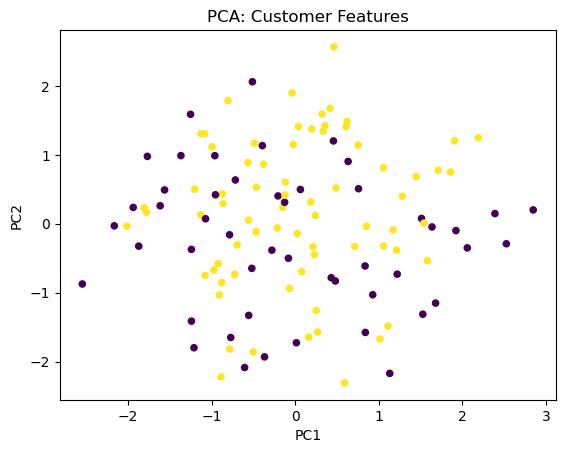

In [23]:
import matplotlib.pyplot as plt
plt.scatter(X_pca[:,0],X_pca[:,1],c=customers['Repeat_Purchase'],cmap='viridis',s=20)
plt.xlabel('PC1');plt.ylabel('PC2');plt.title('PCA: Customer Features');plt.show()

### Explanation
The scatterplot displays customers using two principal components. Colors indicate the target only for visualization; PCA was fitted without the target. Overlapping colors suggest that the first two variance directions may not fully separate classes. This plot is exploratory rather than proof of predictive performance.

## Advantages of PCA

### Definition
Advantages of PCA is a useful concept in feature engineering. It describes a specific way to represent, inspect, or transform information. Its purpose is to make patterns easier to understand without changing what the records mean. The right choice depends on the dataset and the prediction goal.

### Business Example
In a retail business, customer ages, purchase amounts, membership levels, and dates contain different kinds of information. A team may apply advantages of pca while studying repeat purchases. The result can help summarize customer behavior or prepare a reliable prediction system. Business context determines whether the resulting feature is meaningful.

### AI/ML Use
In machine learning, advantages of pca can affect what a model learns from the training data. It should be applied only when the information would be available at prediction time. Any learned parameters must be fitted using training data rather than test data. The usefulness of the result should be checked on held-out observations.

### Python Example

In [25]:
print('Four numeric columns reduced to:',X_pca.shape[1]);print('Variance retained:',round(pca.explained_variance_ratio_.sum(),3))

Four numeric columns reduced to: 2
Variance retained: 0.589


### Explanation
This example demonstrates advantages of pca with the customer shopping dataset. Run the cell to inspect its result. Notice which columns are used and what changes in the output. In a real project, compare the result with the original data and check that no future or target information has leaked.

## Limitations of PCA

### Definition
Limitations of PCA is a useful concept in feature engineering. It describes a specific way to represent, inspect, or transform information. Its purpose is to make patterns easier to understand without changing what the records mean. The right choice depends on the dataset and the prediction goal.

### Business Example
In a retail business, customer ages, purchase amounts, membership levels, and dates contain different kinds of information. A team may apply limitations of pca while studying repeat purchases. The result can help summarize customer behavior or prepare a reliable prediction system. Business context determines whether the resulting feature is meaningful.

### AI/ML Use
In machine learning, limitations of pca can affect what a model learns from the training data. It should be applied only when the information would be available at prediction time. Any learned parameters must be fitted using training data rather than test data. The usefulness of the result should be checked on held-out observations.

### Python Example

In [27]:
print('Original names:',list(X_num.columns));print('New names: PC1, PC2')

Original names: ['Age', 'Annual_Income', 'Quantity', 'Product_Price']
New names: PC1, PC2


### Explanation
PCA components mix the original variables, making them harder to interpret. PCA maximizes variance, not predictive relevance. It can discard low-variance signals that are useful for a target. Nonlinear relationships may not be captured well.

## When to use PCA

### Definition
When to use PCA is a useful concept in feature engineering. It describes a specific way to represent, inspect, or transform information. Its purpose is to make patterns easier to understand without changing what the records mean. The right choice depends on the dataset and the prediction goal.

### Business Example
In a retail business, customer ages, purchase amounts, membership levels, and dates contain different kinds of information. A team may apply when to use pca while studying repeat purchases. The result can help summarize customer behavior or prepare a reliable prediction system. Business context determines whether the resulting feature is meaningful.

### AI/ML Use
In machine learning, when to use pca can affect what a model learns from the training data. It should be applied only when the information would be available at prediction time. Any learned parameters must be fitted using training data rather than test data. The usefulness of the result should be checked on held-out observations.

### Python Example

In [29]:
print('Use PCA when numeric features are numerous or correlated and dimensionality reduction is useful.')

Use PCA when numeric features are numerous or correlated and dimensionality reduction is useful.


### Explanation
This example demonstrates when to use pca with the customer shopping dataset. Run the cell to inspect its result. Notice which columns are used and what changes in the output. In a real project, compare the result with the original data and check that no future or target information has leaked.

## When not to use PCA

### Definition
When not to use PCA is a useful concept in feature engineering. It describes a specific way to represent, inspect, or transform information. Its purpose is to make patterns easier to understand without changing what the records mean. The right choice depends on the dataset and the prediction goal.

### Business Example
In a retail business, customer ages, purchase amounts, membership levels, and dates contain different kinds of information. A team may apply when not to use pca while studying repeat purchases. The result can help summarize customer behavior or prepare a reliable prediction system. Business context determines whether the resulting feature is meaningful.

### AI/ML Use
In machine learning, when not to use pca can affect what a model learns from the training data. It should be applied only when the information would be available at prediction time. Any learned parameters must be fitted using training data rather than test data. The usefulness of the result should be checked on held-out observations.

### Python Example

In [31]:
print('Avoid PCA when original feature interpretability is essential or few features already work well.')

Avoid PCA when original feature interpretability is essential or few features already work well.


### Explanation
This example demonstrates when not to use pca with the customer shopping dataset. Run the cell to inspect its result. Notice which columns are used and what changes in the output. In a real project, compare the result with the original data and check that no future or target information has leaked.

## Complete Practical Example
The following example connects the ideas from this notebook.

In [33]:
X_train, X_test = train_test_split(X_num, test_size=0.25, random_state=42)
pca_pipeline = Pipeline([('scale',StandardScaler()),('pca',PCA(n_components=2))])
train_components = pca_pipeline.fit_transform(X_train)
test_components = pca_pipeline.transform(X_test)
print('Train:',train_components.shape,'Test:',test_components.shape)
print('Train-only PCA explained variance:',pca_pipeline.named_steps['pca'].explained_variance_ratio_.round(3))

Train: (90, 2) Test: (30, 2)
Train-only PCA explained variance: [0.311 0.293]
